# PeakWise Phase 1 · Features, validation design and baselines

**What this notebook does.** It turns the audited evening-consumption target into a model-ready
table, fixes a chronological train/validation/test design, and measures how far simple forecasting
rules get. No ensemble is trained here: the point is to know what counts as a *good* result before
Random Forest, XGBoost or stacking are allowed to claim one.

**What it builds on.** The audited target `audit_out/peakwise_target_clean.csv` (464,640 valid
household-days, 2,931 households, 2023-10-01 to 2024-12-22) and the characteristics found in
`00_exploratory_data_analysis.ipynb`. The 45.6-million-row raw pipeline is **not** rebuilt.

**Where the code lives.** All logic is in `phase1.py` next to this notebook, so Phase 2 imports the
same feature builder, the same split definition and the same metric function instead of copying them.
The leakage tests are in `check_leakage.py` and are run at the end of this notebook.

In [1]:
import sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates

PROJECT = Path.cwd().resolve()
if not (PROJECT / "phase1.py").exists():
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT))
import phase1

OUT_DIR = PROJECT / "outputs/phase1"; OUT_DIR.mkdir(parents=True, exist_ok=True)
C_INK, C_PEAK, C_MUTED = "#1f3a4d", "#e8912d", "#8a97a3"
C_SPLIT = {"train": "#1f5f7a", "val": "#e8912d", "test": "#c0392b"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.constrained_layout.use": True})
save = lambda fig, n: fig.savefig(OUT_DIR / f"{n}.png", dpi=130, bbox_inches="tight")
print("project root:", PROJECT.name)

project root: peakwise


## 1. The prediction problem, stated precisely

For household *h* and day *D*:

> **y(h, D)** = grid import in kWh between 18:30 and 22:30 on day *D*.
> The forecast is produced **at the end of day D − 1**, so a feature may use readings only up to
> 23:59 on *D* − 1.

That cut-off is the whole design constraint. It is what makes `lag1` (yesterday's evening, which
finished at 22:30 on *D* − 1) legal, and what makes *any* statistic computed over the full history,
such as a household mean over the entire dataset, illegal. Section 6 tests the constraint rather
than asserting it.

In [2]:
target = phase1.load_target(PROJECT / "audit_out")
print(f"{len(target):,} valid household-days | {target.household_ID.nunique():,} households | "
      f"{target.date.min().date()} to {target.date.max().date()}")
print(f"y: mean {target.y.mean():.3f} kWh, median {target.y.median():.3f} kWh, "
      f"zeros {100*(target.y==0).mean():.1f}%, max {target.y.max():.2f} kWh")
display(target.head(3))

464,640 valid household-days | 2,931 households | 2023-10-01 to 2024-12-22
y: mean 1.383 kWh, median 0.721 kWh, zeros 8.0%, max 122.95 kWh


,household_ID,date,y,tr2_check
0,ID0013,2024-04-19,0.953,agree
1,ID0013,2024-04-20,0.933,agree
2,ID0013,2024-04-21,0.906,agree


## 2. The feature set, and why each one earns its place

The EDA produced four facts that constrain the design, so the features are chosen against them
rather than by habit:

| Fact from the EDA | Consequence for the features |
|---|---|
| ~46% of quarter-hours missing, mostly **whole days**; one household had a 107-day gap | No feature may *require* yesterday to exist. Every rolling statistic uses a **calendar** window with `min_periods=1`, and the model is told how stale and how thin the history is (`gap_days`, `roll7_n`, `roll28_n`). |
| Target strongly right-skewed, mean (1.38) ≈ 2 × median (0.72) | Level features are **medians**, not means. A mean over a 28-day window would be dragged by one unusual evening. |
| 8.0% of days are exactly 0 kWh; one household was zero on 33% of its days | The recent **share of zeros** is given explicitly (`roll28_frac_zero`); a median alone cannot express "this household is often simply off". |
| Households differ by more than 16× in level | Every level feature is computed **per household**. No global scaling, and no household identifier as an input. |

**Why `household_ID` is deliberately not a feature.** With 2,931 levels it would let a tree memorise
each household rather than learn a rule, and it carries no information that `roll28_median` and
`expanding_median` do not already carry in usable form. Leaving it out also keeps the model usable
for a household that joins later. The household's *identity* is therefore represented by its own
recent behaviour, which is exactly what is available at forecast time.

**Why the weekly features are modest.** The audited target's weekday medians run 0.694 to 0.742 kWh,
a spread of about 7%, so the weekly cycle is weak here. `lag7` and `dow` are kept because a weekly
rhythm is plausible and cheap to include, but no elaborate seasonal encoding is justified by the
data. Section 5 shows that `lag7` is in fact a *worse* predictor than yesterday.

**Features that were considered and rejected:** rolling means and standard deviations (not robust
under this skew, and `roll28_iqr` already measures spread); temperature or holiday calendars (not in
this dataset and not verifiable here); any fitted scaler or target encoding (fits on the training
period and silently changes meaning in the test period); `days_since_start` (invites a tree to
extrapolate a trend into dates it has never seen).

In [3]:
print(f"forecast horizon: {phase1.HORIZON_DAYS} day | windows: {phase1.SHORT_WINDOW} and {phase1.LONG_WINDOW} calendar days\n")
wk = target.assign(dow=target.date.dt.day_name().str[:3]).groupby("dow", sort=False)["y"].median()
print("weekday medians of the target (kWh):", {k: round(v, 3) for k, v in wk.items()},
      f"-> spread {100*(wk.max()/wk.min()-1):.0f}%\n")
display(pd.DataFrame({"feature": phase1.FEATURES,
                      "what it is, and when it becomes known": [phase1.FEATURE_NOTES[f] for f in phase1.FEATURES]})
        .set_index("feature"))

forecast horizon: 1 day | windows: 7 and 28 calendar days

weekday medians of the target (kWh): {'Fri': 0.714, 'Sat': 0.694, 'Sun': 0.71, 'Mon': 0.721, 'Tue': 0.726, 'Wed': 0.739, 'Thu': 0.742} -> spread 7%



,"what it is, and when it becomes known"
feature,
lag1,yesterday's evening kWh (NaN if yesterday is n...
lag7,"same weekday last week, evening kWh (NaN if mi..."
last_value,most recent valid evening kWh on or before D-1...
gap_days,calendar days between D and that most recent v...
roll7_median,median evening kWh over the 7 calendar days D-...
roll28_median,median evening kWh over D-28..D-1: the househo...
roll28_iqr,p75-p25 of the same window: how variable the h...
roll28_frac_zero,share of observed evenings in D-28..D-1 that a...
roll7_n,number of observed evenings in D-7..D-1 (0-7):...


In [4]:
feats = phase1.assign_split(phase1.build_features(target))
print(f"feature rows: {len(feats):,} (one per valid household-day)")
display(feats.loc[feats.household_ID == feats.household_ID.iloc[0], ["date", "y"] + phase1.FEATURES].head(8).round(3))

feature rows: 464,640 (one per valid household-day)


,date,y,lag1,lag7,last_value,gap_days,roll7_median,roll28_median,roll28_iqr,roll28_frac_zero,roll7_n,roll28_n,expanding_median,dow,is_weekend,month
0,2024-04-19,0.953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,4,0,4
1,2024-04-20,0.933,0.953,NaN,0.953,1.0,0.953,0.953,0.000,0.0,1.0,1.0,0.953,5,1,4
2,2024-04-21,0.906,0.933,NaN,0.933,1.0,0.943,0.943,0.010,0.0,2.0,2.0,0.943,6,1,4
3,2024-04-22,0.857,0.906,NaN,0.906,1.0,0.933,0.933,0.024,0.0,3.0,3.0,0.933,0,0,4
4,2024-04-23,1.171,0.857,NaN,0.857,1.0,0.920,0.920,0.044,0.0,4.0,4.0,0.920,1,0,4
5,2024-04-24,1.163,1.171,NaN,1.171,1.0,0.933,0.933,0.047,0.0,5.0,5.0,0.933,2,0,4
6,2024-04-25,1.179,1.163,NaN,1.163,1.0,0.943,0.943,0.198,0.0,6.0,6.0,0.943,3,0,4
7,2024-04-26,1.231,1.179,0.953,1.179,1.0,0.953,0.953,0.248,0.0,7.0,7.0,0.953,4,0,4


**What we are looking at.** The first days of one household. The pattern to notice is that
`roll7_n` and `roll28_n` start at 1 and grow: the features never pretend to know more history than
the household actually has, and `min_periods=1` means an early row is kept with a thin estimate
rather than silently dropped.

## 3. Inclusion and exclusion decisions

One rule, stated once: **a row is kept if the household has at least one observed evening in the
previous 28 days** (`roll28_n >= 1`). Without that, there is no level estimate of any kind and every
level feature is `NaN`; such a row could only be predicted by a global constant.

The threshold is a judgement call, so the table below shows what stricter rules would cost. A
stricter rule buys more reliable features and pays in sample size, mostly for households that report
irregularly. We keep the loosest rule and hand the model `roll28_n` and `gap_days` so that it can
discount a thin history itself, rather than deciding for it.

Rows are **not** excluded for being extreme: the audit established that the large values pass every
physical check, and removing them would flatter every metric that follows.

In [5]:
summary = json.loads((OUT_DIR / "phase1_summary.json").read_text()) if (OUT_DIR / "phase1_summary.json").exists() else None
thresholds = pd.DataFrame({"min observed evenings in the previous 28 days": [1, 3, 7, 14]})
thresholds["rows kept"] = [int((feats.roll28_n.fillna(0) >= k).sum()) for k in thresholds.iloc[:, 0]]
thresholds["share of target kept %"] = (100 * thresholds["rows kept"] / len(feats)).round(2)
thresholds["households kept"] = [int(feats.loc[feats.roll28_n.fillna(0) >= k, "household_ID"].nunique())
                                 for k in thresholds.iloc[:, 0]]
display(thresholds.set_index(thresholds.columns[0]))

model_table = phase1.apply_inclusion(feats, min_history=1)
print(f"\nkept {len(model_table):,} of {len(feats):,} rows "
      f"({len(feats)-len(model_table):,} dropped, {100*(len(feats)-len(model_table))/len(feats):.2f}%)")
print("missing values that remain (% of kept rows):")
print((model_table[phase1.FEATURES].isna().mean() * 100).round(2).loc[lambda s: s > 0].to_string())

,rows kept,share of target kept %,households kept
min observed evenings in the previous 28 days,,,
1,455983,98.14,2925
3,438180,94.31,2921
7,397104,85.46,2908
14,327716,70.53,2898



kept 455,983 of 464,640 rows (8,657 dropped, 1.86%)
missing values that remain (% of kept rows):
lag1             3.66
lag7            17.56
roll7_median     0.85


**What we learn.** Only 1.9% of the audited target is lost, so the inclusion rule is cheap. What
remains missing is informative rather than fatal: `lag7` is absent on about 18% of rows and `lag1`
on about 4%, which is the whole-day gap structure showing through. Those gaps are kept as `NaN`
instead of being filled, because a filled value and an observed value are not the same evidence;
`phase1.fill_missing()` provides a row-local fill with an explicit `_missing` flag for Phase 2
models that cannot take `NaN` directly.

## 4. Validation design

**The requirement.** Forecast the near future for households already observed. So the split must be
chronological, the test period must stay untouched, and the same arrangement must serve Random
Forest, XGBoost and stacking in Phase 2.

**The design.**

| Split | Dates | Role |
|---|---|---|
| train | 2023-10-01 → 2024-09-30 | fit models |
| validation | 2024-10-01 → 2024-11-10 | compare models and tune |
| test | 2024-11-11 → 2024-12-22 | touched once, at the very end |

**Why a plain date cut and not a random split.** A random split would put day *D* in training and day
*D* + 1 in test for the same household, which is exactly the information a real forecaster lacks; it
would flatter every model. **Why not group-by-household.** The project forecasts households it has
already seen, so households deliberately appear in all three splits; the generalisation being
measured is forward in time, not to unseen households.

**Why no embargo gap between splits.** Features reach back up to 28 days, so a validation row's
features use training-period data. That is not leakage: it is precisely what a forecaster standing
on 2024-10-01 would have. The thing that must never happen is the reverse — a training row using the
future — and that is what Section 6 tests.

**Inside the training period**, `phase1.cv_folds()` provides expanding-window folds for Phase 2
tuning, so hyperparameters are never chosen using data that precedes the model's own training window.

In [6]:
split_rows = []
seen_train = set(model_table.loc[model_table.split == "train", "household_ID"])
for name in ("train", "val", "test"):
    s = model_table[model_table.split == name]
    split_rows.append({"split": name, "from": phase1.SPLIT_DATES[name][0], "to": phase1.SPLIT_DATES[name][1],
                       "rows": len(s), "share %": round(100 * len(s) / len(model_table), 1),
                       "households": s.household_ID.nunique(),
                       "households not in train": 0 if name == "train" else int((~s.groupby("household_ID").size().index.isin(seen_train)).sum()),
                       "y median": round(s.y.median(), 3), "y mean": round(s.y.mean(), 3),
                       "zeros %": round(100 * (s.y == 0).mean(), 1),
                       "lag1 missing %": round(100 * s.lag1.isna().mean(), 1),
                       "lag7 missing %": round(100 * s.lag7.isna().mean(), 1)})
display(pd.DataFrame(split_rows).set_index("split"))

print("expanding-window CV folds inside the training period (for Phase 2 tuning):")
for i, (a, b) in enumerate(phase1.cv_folds(model_table), 1):
    d = model_table["date"].iloc[b]
    print(f"  fold {i}: train {len(a):,} rows (up to {model_table['date'].iloc[a].max().date()}) "
          f"-> validate {len(b):,} rows ({d.min().date()} to {d.max().date()})")

,from,to,rows,share %,households,households not in train,y median,y mean,zeros %,lag1 missing %,lag7 missing %
split,,,,,,,,,,,
train,2023-10-01,2024-09-30,315079,69.1,2899,0,0.729,1.461,8.2,4.1,22.8
val,2024-10-01,2024-11-10,82500,18.1,2677,26,0.732,1.241,7.4,3.5,8.9
test,2024-11-11,2024-12-22,58404,12.8,2120,10,0.668,1.171,7.9,1.4,1.7


expanding-window CV folds inside the training period (for Phase 2 tuning):


  fold 1: train 186,108 rows (up to 2024-05-30) -> validate 36,933 rows (2024-05-31 to 2024-07-10)
  fold 2: train 223,041 rows (up to 2024-07-10) -> validate 50,849 rows (2024-07-11 to 2024-08-20)
  fold 3: train 273,890 rows (up to 2024-08-20) -> validate 41,189 rows (2024-08-21 to 2024-09-30)


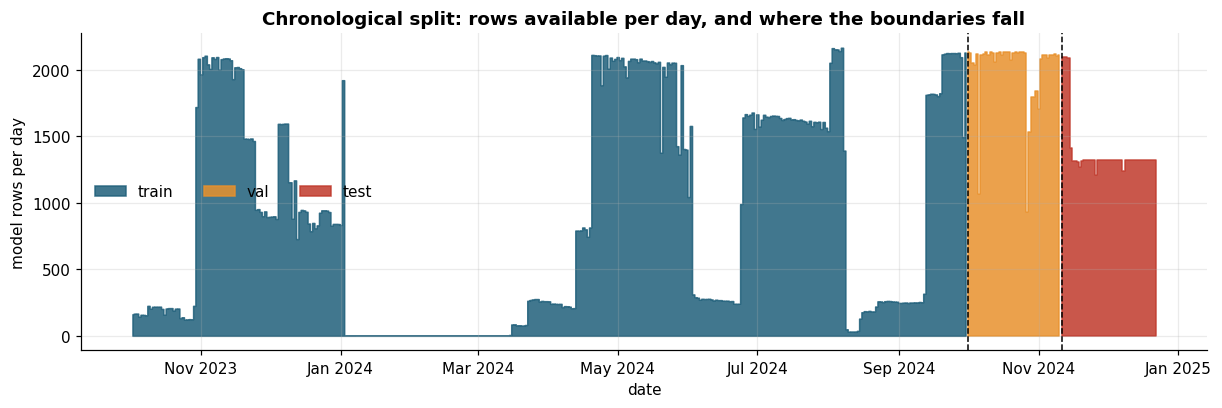

days with no usable rows inside the overall span: 52


In [7]:
daily = model_table.groupby(["date", "split"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
for name in ("train", "val", "test"):
    if name in daily:                       # mask zeros so a split is drawn only where it exists
        v = daily[name].replace(0, np.nan)
        ax.fill_between(v.index, v, color=C_SPLIT[name], alpha=.85, step="mid", label=name)
for name in ("val", "test"):
    ax.axvline(pd.Timestamp(phase1.SPLIT_DATES[name][0]), color="k", lw=1, ls="--")
ax.set_ylabel("model rows per day"); ax.set_xlabel("date")
ax.set_title("Chronological split: rows available per day, and where the boundaries fall")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.legend(ncol=3)
save(fig, "p1_01_splits"); plt.show()
print("days with no usable rows inside the overall span:",
      int((pd.date_range(model_table.date.min(), model_table.date.max()).difference(daily.index)).size))

**What we are looking at.** How many model-ready rows exist on each day, coloured by split.

**What we learn.** The training period is not a smooth block: it carries the collection outages seen
in the EDA (nothing usable between mid-January and late March 2024, thinner stretches in June and
August). Validation and test sit in the dense, recent part of the record, which is the right place
to measure a forecaster that is meant to run tomorrow, but it also means **the test period is easier
than an average stretch of this dataset**: histories there are fresher (`lag1` missing on 1.4% of
test rows versus 4.1% in training). That caveat belongs in the final report.

## 5. Baselines

A baseline here answers "what score does a method deserve credit for beating?". Five of the six are
free, in the sense that they are a single column of the feature table:

| Baseline | Rule | Why it is included |
|---|---|---|
| `global_median` | the training median, for everybody | the floor: what you get with no household knowledge at all |
| `persistence_lag1` | yesterday's evening | the standard naive forecast |
| `persistence_last` | the last observed evening, carried over gaps | the honest version of persistence when yesterday may be missing |
| `seasonal_lag7` | the same weekday last week | the standard *seasonal* naive forecast for daily data with a weekly cycle |
| `roll7_median` / `roll28_median` | median of the last 7 / 28 days | robust level estimates, the natural competitor under a skewed target |
| `expanding_median` | median of the household's entire past | the long-run level, ignoring recent movement |

**Why the median and not the mean, mathematically.** The point forecast that minimises expected
**absolute** error is the conditional *median*; the one that minimises expected **squared** error is
the conditional *mean*. Since this target is strongly right-skewed, those two are far apart, and a
median-based rule should win on MAE. That is a prediction the table below can confirm or refute.

**Reading the metrics, in kWh.**
* **MAE** — the average miss, in kWh. Directly interpretable: an MAE of 0.29 kWh on a median evening
  of 0.67 kWh means a typical forecast is off by roughly 40% of a typical evening.
* **RMSE** — squares the errors first, so a handful of badly missed evenings dominate it. Comparing
  RMSE with MAE says *how concentrated* the errors are.
* **MedAE** — the middle error, which ignores the tail entirely.
* **hh_MAE_mean / hh_MAE_median** — each household's own MAE, averaged (mean) or taken at the middle
  (median) across households. Plain MAE is dominated by the biggest consumers; these ask instead how
  the method does for a *typical household*. (An earlier draft called the median `macro_MAE`, which
  was misleading; both are now named for what they are.)
* **coverage** — the share of rows the method can predict at all. A method that only scores well
  where it is defined is not comparable to one that always answers, so the results are repeated on
  the subset where every baseline is defined.

In [8]:
train_median = float(model_table.loc[model_table.split == "train", "y"].median())
print(f"global_median baseline = training median = {train_median:.3f} kWh (fitted on the training split only)")
res = []
for sp in ("val", "test"):
    s = model_table[model_table.split == sp]
    for common in (False, True):
        r = phase1.evaluate(s, train_median, restrict_common=common)
        r.insert(0, "split", sp); r.insert(1, "subset", "common rows" if common else "all rows")
        res.append(r)
results = pd.concat(res, ignore_index=True)
show = results[results.subset == "all rows"].pivot(index="baseline", columns="split",
                                                   values=["MAE", "RMSE", "MedAE", "hh_MAE_mean", "hh_MAE_median", "coverage"])
display(show.swaplevel(axis=1).sort_index(axis=1).round(4))

global_median baseline = training median = 0.729 kWh (fitted on the training split only)


split               test                                                     \
                     MAE   MedAE    RMSE coverage hh_MAE_mean hh_MAE_median   
baseline                                                                      
expanding_median  0.3734  0.1461  2.2116   1.0000      0.3671        0.1881   
global_median     0.8687  0.4020  3.6378   1.0000      0.8510        0.4002   
persistence_lag1  0.3276  0.1220  1.8117   0.9855      0.3300        0.1783   
persistence_last  0.3286  0.1220  1.8030   1.0000      0.3317        0.1790   
roll28_median     0.3039  0.1135  1.8975   1.0000      0.3004        0.1616   
roll7_median      0.2917  0.1090  1.7053   0.9999      0.2929        0.1583   
seasonal_lag7     0.3691  0.1470  1.7203   0.9829      0.3724        0.2111   

split                val                                                     
                     MAE   MedAE    RMSE coverage hh_MAE_mean hh_MAE_median  
baseline                                                                     
expanding_median  0.3753  0.1509  1.1250   1.0000      0.4186        0.2009  
global_median     0.9033  0.4390  2.5776   1.0000      1.0067        0.4449  
persistence_lag1  0.3566  0.1320  1.0610   0.9649      0.3857        0.1934  
persistence_last  0.3586  0.1329  1.0597   1.0000      0.3906        0.1944  
roll28_median     0.3253  0.1205  1.0528   1.0000      0.3549        0.1718  
roll7_median      0.3159  0.1165  1.0102   0.9998      0.3471        0.1688  
seasonal_lag7     0.4112  0.1550  1.1261   0.9114      0.4199        0.2164

best baseline on test: roll7_median  MAE 0.2917 kWh, RMSE 1.7053, hh_MAE_mean 0.2929, hh_MAE_median 0.1583
  improvement over persistence_last: 11.2% MAE
  improvement over global_median:    66.4% MAE
  RMSE / MAE = 5.8  (a symmetric error distribution would give about 1.25)


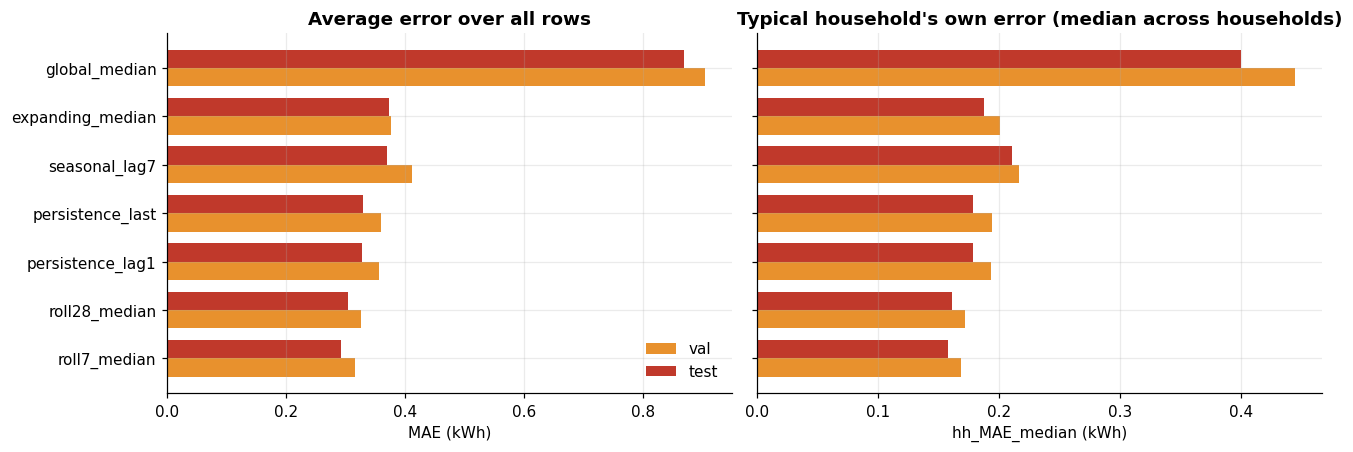

In [9]:
best = results[(results.split == "test") & (results.subset == "all rows")].sort_values("MAE").iloc[0]
naive = results[(results.split == "test") & (results.subset == "all rows") & (results.baseline == "persistence_last")].iloc[0]
flat = results[(results.split == "test") & (results.subset == "all rows") & (results.baseline == "global_median")].iloc[0]
print(f"best baseline on test: {best.baseline}  MAE {best.MAE:.4f} kWh, RMSE {best.RMSE:.4f}, hh_MAE_mean {best.hh_MAE_mean:.4f}, hh_MAE_median {best.hh_MAE_median:.4f}")
print(f"  improvement over persistence_last: {100*(1-best.MAE/naive.MAE):.1f}% MAE")
print(f"  improvement over global_median:    {100*(1-best.MAE/flat.MAE):.1f}% MAE")
print(f"  RMSE / MAE = {best.RMSE/best.MAE:.1f}  (a symmetric error distribution would give about 1.25)")

t = results[results.subset == "all rows"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
order = t[t.split == "test"].sort_values("MAE").baseline.tolist()
for a, metric in zip(ax, ["MAE", "hh_MAE_median"]):
    w = .38
    for i, sp in enumerate(("val", "test")):
        v = t[t.split == sp].set_index("baseline").loc[order, metric]
        a.barh(np.arange(len(order)) + (i - .5) * w, v, height=w, color=C_SPLIT[sp], label=sp)
    a.set_yticks(range(len(order))); a.set_yticklabels(order); a.invert_yaxis()
    a.set_xlabel(f"{metric} (kWh)"); a.set_title("Average error over all rows" if metric == "MAE"
                                                 else "Typical household's own error (median across households)")
ax[0].legend()
save(fig, "p1_02_baselines"); plt.show()

**What we learn.**

1. **The rolling median wins, as the theory predicts.** `roll7_median` is the best baseline on both
   validation and test. Under a right-skewed target, the MAE-optimal forecast is a conditional
   median, and the rule that estimates one does best.
2. **Seasonal persistence is the *worst* of the history-based rules**, worse even than plain
   persistence. The weekly cycle in this dataset is too weak to pay for the extra staleness of a
   seven-day-old observation. This retires "same weekday last week" as a serious competitor and
   confirms the EDA's weekday finding from a different direction.
3. **RMSE is roughly six times MAE.** The error distribution is as skewed as the target: most days
   are forecast closely and a few are missed badly. Phase 2 should therefore report MAE and RMSE
   side by side, because the two can rank models differently.
4. **A household-level view is kinder than the global one** (`hh_MAE_median` ≈ 0.16 kWh versus MAE
   ≈ 0.29 kWh): the global average is carried by the minority of large consumers.
5. **Coverage matters.** `persistence_lag1` and `seasonal_lag7` cannot answer on every row; their
   scores on "all rows" are computed where they are defined. On the common subset the ranking is
   unchanged, so the conclusion does not depend on that choice.

### Where the error actually comes from

Two breakdowns of the best baseline's error, because they decide what Phase 2 should optimise.

In [10]:
s = model_table[model_table.split == "test"].copy()
s["pred"] = s["roll7_median"].fillna(s["last_value"])
s["abs_err"] = (s.pred - s.y).abs()
q = model_table.loc[model_table.split == "train", "y"].quantile([.25, .75, .95, .99])
bands = pd.cut(s.y, [-.01, 0, q[.25], q[.75], q[.95], q[.99], np.inf],
               labels=["exactly 0", "low (<P25)", "typical (P25-P75)", "high (P75-P95)", "very high (P95-P99)", "extreme (>P99)"])
tbl = pd.DataFrame({"rows": s.groupby(bands, observed=True).size(),
                    "share of rows %": (100 * s.groupby(bands, observed=True).size() / len(s)).round(1),
                    "MAE (kWh)": s.abs_err.groupby(bands, observed=True).mean().round(3),
                    "share of all error %": (100 * s.abs_err.groupby(bands, observed=True).sum() / s.abs_err.sum()).round(1)})
display(tbl)

# staleness: the test period has very few stale rows, so validation is shown beside it
stale = []
for sp in ("val", "test"):
    v = model_table[model_table.split == sp].copy()
    v["abs_err"] = (v["roll7_median"].fillna(v["last_value"]) - v.y).abs()
    g = pd.cut(v.gap_days, [0, 1, 2, 7, np.inf], labels=["1 (yesterday)", "2", "3-7", "more than 7"])
    stale.append(pd.DataFrame({(sp, "rows"): v.groupby(g, observed=True).size(),
                               (sp, "MAE (kWh)"): v.abs_err.groupby(g, observed=True).mean().round(3)}))
display(pd.concat(stale, axis=1))

,rows,share of rows %,MAE (kWh),share of all error %
y,,,,
exactly 0,4604,7.9,0.061,1.6
low (<P25),10566,18.1,0.130,8.1
typical (P25-P75),32701,56.0,0.206,39.6
high (P75-P95),8988,15.4,0.547,28.9
very high (P95-P99),1136,1.9,1.605,10.7
extreme (>P99),409,0.7,4.614,11.1


val             test          
                rows MAE (kWh)   rows MAE (kWh)
gap_days                                       
1 (yesterday)  79603     0.315  57559     0.291
2               2185     0.318    816     0.340
3-7              693     0.395     21     1.419
more than 7       19     0.544      8     0.195

**What we learn.** The two breakdowns point the same way.

* The 2.6% of test evenings that sit above the training 95th percentile carry **22% of all absolute
  error**, and the extreme band above the 99th percentile is missed by 4.6 kWh on average. Any Phase 2 gain will come mostly from
  these days, and any metric that hides them (MedAE alone) will hide the gain too.
* **Error grows as the history goes stale**: on validation, MAE rises from 0.315 kWh when yesterday
  is available to 0.395 kWh when the last observation is 3-7 days old. The test period has only 21
  such rows, so that column is read from validation. `gap_days` is therefore not decoration;
  it is the feature that lets a model widen its own uncertainty. The test period has few stale rows,
  which is another reason it is an optimistic sample.

## 6. Temporal leakage checks

Claiming "no leakage" is not evidence. `check_leakage.py` is a test suite that would fail loudly if
a feature of day *D* could see day *D* or later. The decisive one is **future corruption**: multiply
every target after a cut-off date by 1000, rebuild the features, and require that every feature of
every earlier row is bit-for-bit unchanged. A leak of any kind — a centred window, a `shift` in the
wrong direction, a statistic fitted on the whole period — moves at least one of those numbers.

The suite also checks that a row cannot see **its own** target, recomputes every feature for 250
randomly sampled real rows by brute-force date filtering (`date <= D-1`) and compares, verifies the
split boundaries do not overlap, and verifies that the optional `fill_missing()` helper copies only
from the same row.

In [11]:
r = subprocess.run([sys.executable, "check_leakage.py"], cwd=PROJECT, capture_output=True, text=True)
print(r.stdout[-400:] + r.stderr[-2500:])
assert r.returncode == 0, "leakage tests FAILED - do not proceed to Phase 2"

test_no_feature_equals_the_target (__main__.FeaturesMatchAnAsOfRecomputation) ... ok
test_sampled_rows (__main__.FeaturesMatchAnAsOfRecomputation) ... ok
test_fill_is_row_local_and_flagged (__main__.FillingDoesNotInventInformation) ... ok
test_filled_table_has_no_missing_values_left (__main__.FillingDoesNotInventInformation)
A plain RandomForestRegressor must be able to consume the filled table as-is. ... ok
test_real_target_sample (__main__.FutureCannotReachThePast) ... ok
test_row_cannot_see_its_own_target (__main__.FutureCannotReachThePast) ... ok
test_synthetic_panel (__main__.FutureCannotReachThePast) ... ok
test_assigned_rows_respect_the_order (__main__.SplitsAreChronological) ... ok
test_boundaries_do_not_overlap (__main__.SplitsAreChronological) ... ok

----------------------------------------------------------------------
Ran 9 tests in 1.751s

OK



In [12]:
cols = ["household_ID", "date", "split", "y", "tr2_check"] + phase1.FEATURES
model_table[cols].to_csv(OUT_DIR / "model_table.csv.gz", index=False)
results.to_csv(OUT_DIR / "baseline_metrics.csv", index=False)
print(f"wrote {(OUT_DIR/'model_table.csv.gz').relative_to(PROJECT)}  ({len(model_table):,} rows x {len(cols)} columns)")
print(f"wrote {(OUT_DIR/'baseline_metrics.csv').relative_to(PROJECT)}")
print("\ntr2_check composition of the model table:", model_table.tr2_check.value_counts().to_dict())
print("\nPhase 2 starts from exactly this:")
print("    import phase1")
print("    m = pd.read_csv('outputs/phase1/model_table.csv.gz', parse_dates=['date'])")
print("    X, y = m[phase1.FEATURES], m['y']          # XGBoost / HistGradientBoosting: NaN is fine")
print("    g = phase1.fill_missing(m); Xf = g[phase1.FILLED_FEATURES]   # RandomForest: filled + flagged")
print("    folds = phase1.cv_folds(m)                 # tuning inside the training period")
print("    phase1.metrics(y_true, y_pred, households) # the same metric function used above")

wrote outputs/phase1/model_table.csv.gz  (455,983 rows x 19 columns)
wrote outputs/phase1/baseline_metrics.csv

tr2_check composition of the model table: {'agree': 326513, 'no_bracket': 125935, 'plateau_inconsistent': 2494, 'disagree': 1041}

Phase 2 starts from exactly this:
    import phase1
    m = pd.read_csv('outputs/phase1/model_table.csv.gz', parse_dates=['date'])
    X, y = m[phase1.FEATURES], m['y']          # XGBoost / HistGradientBoosting: NaN is fine
    g = phase1.fill_missing(m); Xf = g[phase1.FILLED_FEATURES]   # RandomForest: filled + flagged
    folds = phase1.cv_folds(m)                 # tuning inside the training period
    phase1.metrics(y_true, y_pred, households) # the same metric function used above


## 7. Summary and what Phase 2 should do

**The design in one paragraph.** 455,983 model rows (98.1% of the audited target) over 2,931
households, each with 14 features computed only from that household's own evenings up to the end of
day *D* − 1: three recency features (`lag1`, `lag7`, `last_value`), four level and shape features
(`roll7_median`, `roll28_median`, `roll28_iqr`, `roll28_frac_zero`), three history-quality features
(`gap_days`, `roll7_n`, `roll28_n`), the long-run `expanding_median`, and three calendar features.
Split chronologically into train (315,079 rows), validation (82,500) and test (58,404), with the test
period opened only once at the end, and expanding-window folds available inside training for tuning.

**The bar to beat.** On the untouched test period the best simple rule, a 7-day rolling median, gets
**MAE 0.292 kWh, RMSE 1.705 kWh, median-household MAE 0.158 kWh**. Persistence gets MAE 0.329 and a global
constant 0.869. An ensemble that does not clearly beat 0.292 kWh has not earned its complexity.

**Recommendations for the ensembles.**

1. **Compare on validation only, and open the test period once.** Use `phase1.cv_folds()` for
   hyperparameters, the validation split to choose between model families, and the test split for
   the single final number of each model.
2. **Expect the gain to come from the skewed tail.** Report MAE *and* RMSE *and* the per-household MAE (mean and median) together,
   and consider training on `log1p(y)` for a variance-stabilised fit while still reporting errors in
   kWh — but check it both ways, because back-transforming a conditional mean of logs is biased, and
   MAE rewards predicting the median.
3. **Let the models use `NaN` where they can.** XGBoost 2.1.4 and scikit-learn 1.6.1's
   `HistGradientBoostingRegressor` both take `NaN` directly, so feed them `m[phase1.FEATURES]`. A
   plain `RandomForestRegressor` cannot, so use `phase1.fill_missing(m)[phase1.FILLED_FEATURES]`,
   which fills `lag1`, `lag7` and `roll7_median` from the same row's `last_value`/`roll28_median`
   and adds a `*_missing` flag for each, so a filled value is never mistaken for an observed one.
4. **Keep the stacking honest.** The meta-learner must be trained on *out-of-fold* predictions from
   the chronological folds, never on predictions the base models made for their own training rows,
   or the stack will learn to trust an overfitted base model.
5. **Two sanity checks worth the minutes they cost.** Confirm that a tuned model beats `roll7_median`
   for a *typical household* (hh_MAE_median) and not only on average; and re-score on the rows the audit marked
   `tr2_check == "agree"` (326,513 of the 455,983 model rows) to confirm that nothing rests on the days the meter's own
   register disputes.

**Honest limitations of this phase.** The test period is the densest, freshest part of the record,
so its scores are optimistic relative to an average stretch of this dataset. Households are not
disjoint across splits by design, so nothing here measures generalisation to a household never seen
before. No weather, tariff or holiday information is used, because none is present in the audited
data. And the inclusion rule, the 7- and 28-day windows and the split dates are reasoned choices,
not optimised ones: they were fixed before any model was fitted, and should stay fixed.